# 🤖 02. Supervised Machine Learning Threat Classification & White-Box Interpretability
**Project:** AI in Cyber Security Capstone (Unit 1)  
**Dataset:** UNSW-NB15 Modern Network Intrusion Benchmark  
**Author:** Anant Goel  
**Objective:** End-to-end implementation of enterprise preprocessing, high-cardinality categorical handling, StandardScaler normalization, stratified train/validation splitting, Logistic Regression and Decision Tree training, multi-metric diagnostics, Top-15 Feature Importances, granular per-threat-category False Negative audit, and SOC decision threshold tuning.

---


In [1]:
# 1. Environment & Analytical Setup
import sys
import os
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve
)

# Visual Aesthetics Configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 120

print("=" * 65)
print("  ENVIRONMENT INITIALIZED FOR SUPERVISED MACHINE LEARNING")
print("=" * 65)
print(f"[✓] Python Version : {sys.version.split()[0]}")
print(f"[✓] Scikit-Learn   : {sklearn.__version__}")
print("=" * 65)


  ENVIRONMENT INITIALIZED FOR SUPERVISED MACHINE LEARNING
[✓] Python Version : 3.13.2
[✓] Scikit-Learn   : 1.9.1


## 🛠️ 2. Enterprise Preprocessing Pipeline & Stratified Splitting
1. **Feature Sanitization**: Drop non-predictive flow index (`id`), synthetic helper columns (`log_rate`), and the multi-class ground truth (`attack_cat`).
2. **Missing Value Audit**: Ensure no NaN/null records corrupt gradient computation.
3. **High-Cardinality Categorical Encoding**:
   - `proto` contains 131 distinct protocols. Encoding all 131 would trigger the curse of dimensionality and severe matrix sparsity. We group rare protocols outside the top 10 into `'other'`, followed by `OneHotEncoder`.
   - `service` and `state` are standard low-cardinality features, encoded via `OneHotEncoder`.
4. **Feature Normalization (`StandardScaler`)**:
   - Network flow attributes span enormous dynamic ranges (e.g. `sbytes` varies from 0 to $>10^7$ bytes, while `dur` is measured in fractions of a millisecond).
   - We apply Z-score standardization ($z = \frac{x - \mu}{\sigma}$) so that distance-based and gradient-based models converge stably without feature dominance.
5. **Stratified Train-Validation Splitting**:
   - Split 75% for training (61,749 flows) and 25% for validation (20,583 flows), preserving the exact class ratio.


In [2]:
# 2. Pipeline Execution
train_path = os.path.join('..', 'data', 'UNSW_NB15_training-set.csv') if os.path.exists(os.path.join('..', 'data')) else os.path.join('data', 'UNSW_NB15_training-set.csv')
df_train = pd.read_csv(train_path)

drop_cols = ['id', 'attack_cat', 'label']
if 'log_rate' in df_train.columns:
    drop_cols.append('log_rate')

X_raw = df_train.drop(columns=drop_cols)
y = df_train['label']
attack_cats_all = df_train['attack_cat']

null_count = X_raw.isnull().sum().sum()
print(f"[✓] Missing Value Audit: {null_count} null entries detected.")

cat_cols = ['proto', 'service', 'state']
num_cols = [c for c in X_raw.columns if c not in cat_cols]

# Group rare protocols outside top 10
top_10_protos = X_raw['proto'].value_counts().nlargest(10).index
X_raw['proto'] = X_raw['proto'].apply(lambda x: x if x in top_10_protos else 'other')

# Construct ColumnTransformer Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# Stratified Splitting
X_train_raw, X_val_raw, y_train, y_val, cat_train, cat_val = train_test_split(
    X_raw, y, attack_cats_all, test_size=0.25, random_state=42, stratify=y
)

X_train = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)

encoded_cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols).tolist()
all_feature_names = num_cols + encoded_cat_names

print(f"[✓] Processed Training Feature Matrix  : {X_train.shape[0]:,} samples x {X_train.shape[1]} features")
print(f"[✓] Processed Validation Feature Matrix: {X_val.shape[0]:,} samples x {X_val.shape[1]} features")


[✓] Missing Value Audit: 0 null entries detected.


[✓] Processed Training Feature Matrix  : 61,749 samples x 69 features
[✓] Processed Validation Feature Matrix: 20,583 samples x 69 features


## 🚀 3. Supervised Model Implementations
- **Logistic Regression**: Linear decision boundary optimized with $L2$ weight regularization (`lbfgs`).
- **Decision Tree Classifier**: Non-linear hierarchical model (`max_depth=12`, `min_samples_split=20`), capable of capturing complex non-linear boundary splits while remaining fully interpretable.


In [3]:
# Train Supervised Machine Learning Models
print("Training Baseline Model 1: Logistic Regression...")
t0_lr = time.time()
lr_model = LogisticRegression(max_iter=500, random_state=42, solver='lbfgs')
lr_model.fit(X_train, y_train)
train_time_lr = time.time() - t0_lr

y_pred_lr = lr_model.predict(X_val)
y_prob_lr = lr_model.predict_proba(X_val)[:, 1]

print("Training Baseline Model 2: Decision Tree Classifier...")
t0_dt = time.time()
dt_model = DecisionTreeClassifier(max_depth=12, min_samples_split=20, random_state=42)
dt_model.fit(X_train, y_train)
train_time_dt = time.time() - t0_dt

y_pred_dt = dt_model.predict(X_val)
y_prob_dt = dt_model.predict_proba(X_val)[:, 1]

print(f"\nLogistic Regression Training Latency: {train_time_lr:.2f} seconds")
print(f"Decision Tree Training Latency      : {train_time_dt:.2f} seconds")


Training Baseline Model 1: Logistic Regression...


Training Baseline Model 2: Decision Tree Classifier...



Logistic Regression Training Latency: 3.99 seconds
Decision Tree Training Latency      : 1.48 seconds


## 📊 4. Multi-Metric Diagnostics & Evaluation
In cybersecurity threat detection, accuracy alone is insufficient. We evaluate:
- **Threat Detection Recall ($TP / (TP + FN)$)**: The percentage of real cyber intrusions intercepted before compromise.
- **Threat Precision ($TP / (TP + FP)$)**: The percentage of security alerts that represent actual attacks.
- **False Positive Rate ($FP / (FP + TN)$)**: The rate of benign traffic mistakenly flagged, causing analyst alert fatigue.
- **ROC-AUC & PR-AUC**: Global separability across continuous probability distributions.


In [4]:
# Evaluation Function for Model Diagnostics
def evaluate_cyber_model(name, y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    
    pr_prec, pr_rec, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(pr_rec, pr_prec)
    
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    fpr_rate = fp / (fp + tn)
    fnr_rate = fn / (fn + tp)
    
    print(f"\n{'=' * 65}")
    print(f"  MODEL EVALUATION REPORT: {name.upper()}")
    print(f"{'=' * 65}")
    print(f"Overall Accuracy       : {acc * 100:.2f}%")
    print(f"Threat Detection Recall: {rec * 100:.2f}% (True Positives: {tp:,} / {tp+fn:,})")
    print(f"Threat Precision       : {prec * 100:.2f}%")
    print(f"F1-Score               : {f1 * 100:.2f}%")
    print(f"ROC-AUC Score          : {roc_auc:.4f}")
    print(f"PR-AUC Score           : {pr_auc:.4f}")
    print(f"False Positive Rate    : {fpr_rate * 100:.2f}% (False Alarms: {fp:,})")
    print(f"False Negative Rate    : {fnr_rate * 100:.2f}% (Missed Breaches: {fn:,})")
    print("\nDetailed Classification Report:")
    print(classification_report(y_true, y_pred, target_names=['Normal (0)', 'Attack (1)']))
    
    return {
        'name': name, 'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1,
        'roc_auc': roc_auc, 'pr_auc': pr_auc, 'fpr_rate': fpr_rate, 'fnr_rate': fnr_rate,
        'fpr': fpr, 'tpr': tpr, 'pr_prec': pr_prec, 'pr_rec': pr_rec, 'cm': cm
    }

metrics_lr = evaluate_cyber_model("Logistic Regression", y_val, y_pred_lr, y_prob_lr)
metrics_dt = evaluate_cyber_model("Decision Tree Classifier", y_val, y_pred_dt, y_prob_dt)



  MODEL EVALUATION REPORT: LOGISTIC REGRESSION
Overall Accuracy       : 91.73%
Threat Detection Recall: 92.27% (True Positives: 10,457 / 11,333)
Threat Precision       : 92.68%
F1-Score               : 92.47%
ROC-AUC Score          : 0.9773
PR-AUC Score           : 0.9829
False Positive Rate    : 8.93% (False Alarms: 826)
False Negative Rate    : 7.73% (Missed Breaches: 876)

Detailed Classification Report:
              precision    recall  f1-score   support

  Normal (0)       0.91      0.91      0.91      9250
  Attack (1)       0.93      0.92      0.92     11333

    accuracy                           0.92     20583
   macro avg       0.92      0.92      0.92     20583
weighted avg       0.92      0.92      0.92     20583


  MODEL EVALUATION REPORT: DECISION TREE CLASSIFIER
Overall Accuracy       : 96.57%
Threat Detection Recall: 96.04% (True Positives: 10,884 / 11,333)
Threat Precision       : 97.70%
F1-Score               : 96.86%
ROC-AUC Score          : 0.9912
PR-AUC Score  

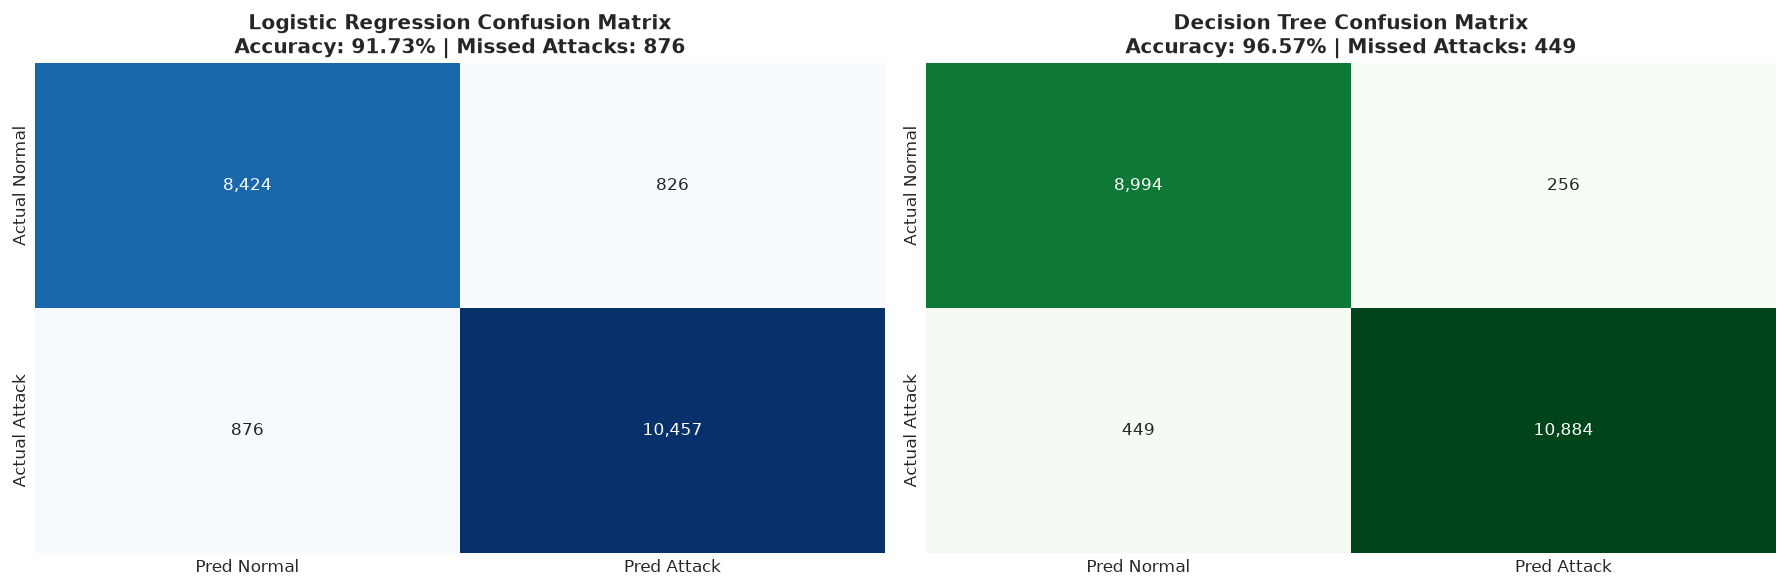

In [5]:
# Confusion Matrices Visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(metrics_lr['cm'], annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Pred Normal', 'Pred Attack'], yticklabels=['Actual Normal', 'Actual Attack'])
axes[0].set_title(f'Logistic Regression Confusion Matrix\nAccuracy: {metrics_lr["accuracy"]*100:.2f}% | Missed Attacks: {metrics_lr["cm"][1, 0]:,}', fontsize=12, weight='bold')

sns.heatmap(metrics_dt['cm'], annot=True, fmt=',d', cmap='Greens', cbar=False, ax=axes[1],
            xticklabels=['Pred Normal', 'Pred Attack'], yticklabels=['Actual Normal', 'Actual Attack'])
axes[1].set_title(f'Decision Tree Confusion Matrix\nAccuracy: {metrics_dt["accuracy"]*100:.2f}% | Missed Attacks: {metrics_dt["cm"][1, 0]:,}', fontsize=12, weight='bold')

plt.tight_layout()
plt.show()


## 🔍 5. Feature Importance & White-Box Rule Interpretability
A paramount advantage of Decision Trees in cyber defense is **white-box explainability**. When an automated IPS blocks traffic, security engineers need to inspect the exact heuristic rule that triggered the block.


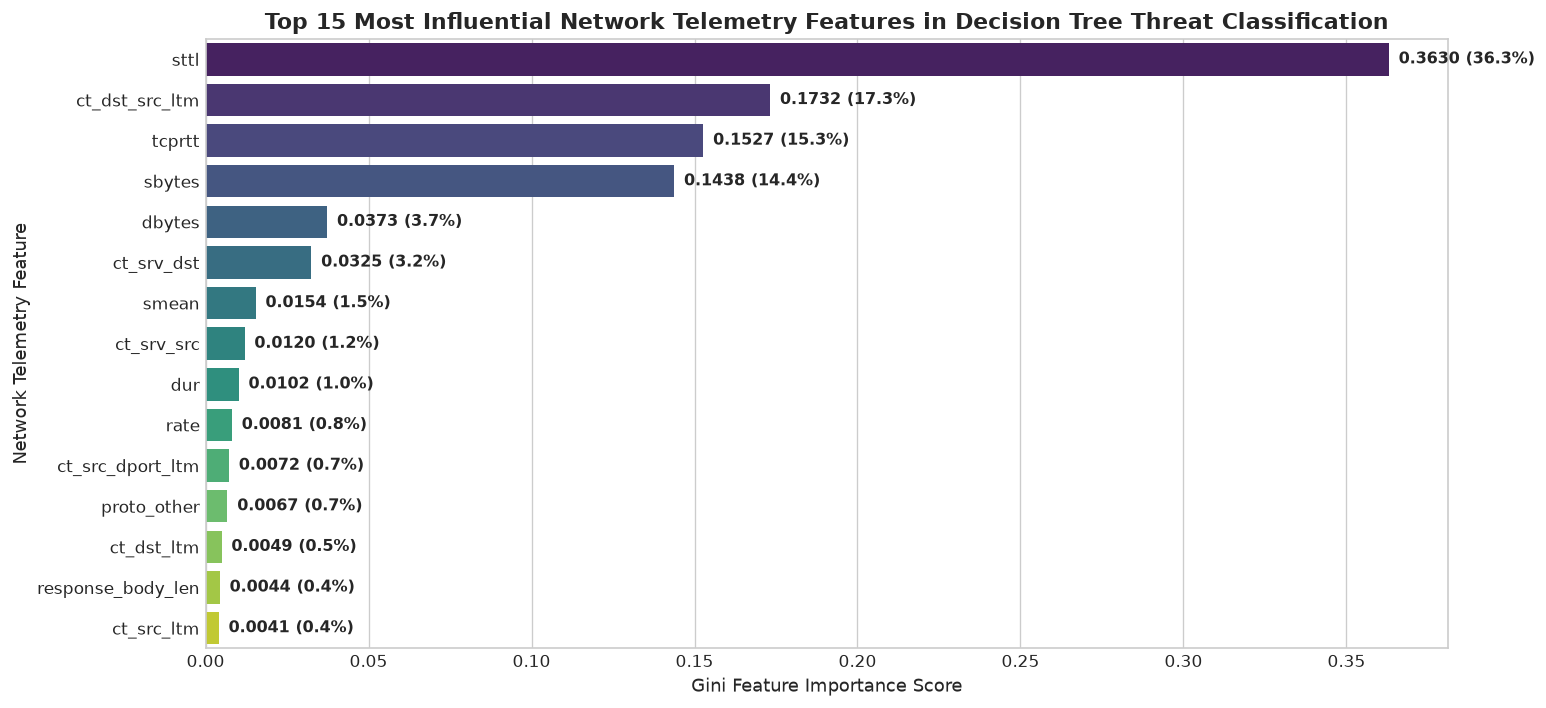

Top 5 Decision Tree Root Telemetry Features:
  1. sttl                 : 36.30% of total tree splitting criteria
  2. ct_dst_src_ltm       : 17.32% of total tree splitting criteria
  3. tcprtt               : 15.27% of total tree splitting criteria
  4. sbytes               : 14.38% of total tree splitting criteria
  5. dbytes               : 3.73% of total tree splitting criteria


In [6]:
# Top 15 Feature Importances in Decision Tree
dt_importances = pd.Series(dt_model.feature_importances_, index=all_feature_names)
top_15_features = dt_importances.nlargest(15)

plt.figure(figsize=(13, 6))
sns.barplot(x=top_15_features.values, y=top_15_features.index, palette='viridis')
plt.title('Top 15 Most Influential Network Telemetry Features in Decision Tree Threat Classification', fontsize=13, weight='bold')
plt.xlabel('Gini Feature Importance Score', fontsize=11)
plt.ylabel('Network Telemetry Feature', fontsize=11)

for i, v in enumerate(top_15_features.values):
    plt.text(v + 0.003, i, f"{v:.4f} ({v*100:.1f}%)", va='center', fontsize=9.5, weight='bold')

plt.tight_layout()
plt.show()

print("Top 5 Decision Tree Root Telemetry Features:")
for rank, (feat, score) in enumerate(top_15_features.head(5).items(), 1):
    print(f"  {rank}. {feat:<20} : {score*100:.2f}% of total tree splitting criteria")


## 🛡️ 6. Threat Family Detection Audit (False Negative Analysis)
While overall accuracy is high (~96.6%), in security operations, **the real question is: Which specific attack families slip past the detector?**
- Do noisy attacks like DoS and Generic get caught 99% of the time?
- Do stealthy, low-volume threats like Backdoors, Worms, and Fuzzers escape detection?


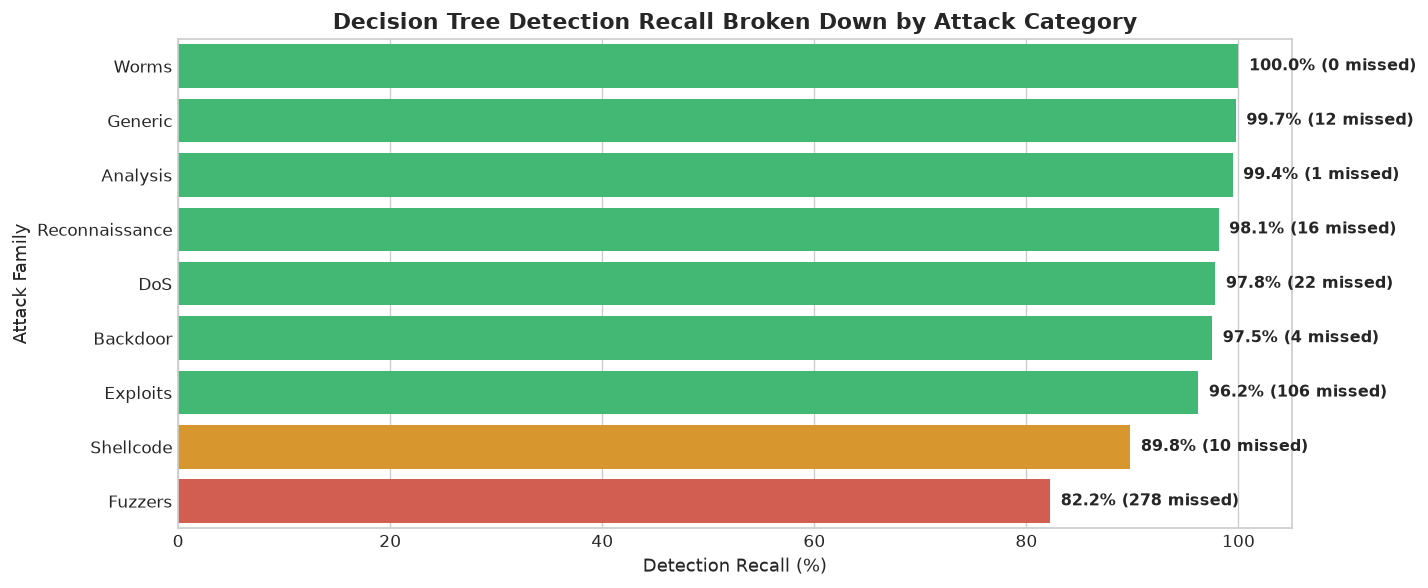

Per-Attack Family Audit Table:


,Total_Attacks,Detected_Attacks,Detection_Recall_%,Missed_Breaches
attack_cat,,,,
Worms,5,5,100.000000,0
Generic,4678,4666,99.743480,12
Analysis,177,176,99.435028,1
Reconnaissance,850,834,98.117647,16
DoS,1006,984,97.813121,22
Backdoor,161,157,97.515528,4
Exploits,2793,2687,96.204798,106
Shellcode,98,88,89.795918,10
Fuzzers,1565,1287,82.236422,278


In [7]:
# Audit Detection Recall per Threat Family
val_df_audit = pd.DataFrame({
    'attack_cat': cat_val,
    'actual_label': y_val,
    'predicted_label': y_pred_dt
})

attack_audit = val_df_audit[val_df_audit['actual_label'] == 1].groupby('attack_cat').agg(
    Total_Attacks=('actual_label', 'count'),
    Detected_Attacks=('predicted_label', 'sum')
)
attack_audit['Detection_Recall_%'] = (attack_audit['Detected_Attacks'] / attack_audit['Total_Attacks']) * 100
attack_audit['Missed_Breaches'] = attack_audit['Total_Attacks'] - attack_audit['Detected_Attacks']
attack_audit = attack_audit.sort_values(by='Detection_Recall_%', ascending=False)

plt.figure(figsize=(12, 5))
palette_audit = ['#2ECC71' if r >= 95 else '#F39C12' if r >= 85 else '#E74C3C' for r in attack_audit['Detection_Recall_%']]
ax = sns.barplot(x=attack_audit['Detection_Recall_%'], y=attack_audit.index, palette=palette_audit)
plt.title('Decision Tree Detection Recall Broken Down by Attack Category', fontsize=13, weight='bold')
plt.xlabel('Detection Recall (%)', fontsize=11)
plt.ylabel('Attack Family', fontsize=11)
plt.xlim(0, 105)

for idx, (cat, row) in enumerate(attack_audit.iterrows()):
    ax.text(row['Detection_Recall_%'] + 1, idx, f"{row['Detection_Recall_%']:.1f}% ({row['Missed_Breaches']:.0f} missed)", va='center', fontsize=9.5, weight='bold')

plt.tight_layout()
plt.show()

print("Per-Attack Family Audit Table:")
display(attack_audit)


## 🎯 7. SOC Alert Fatigue & Decision Threshold Optimization
In a Security Operations Center (SOC), the default 0.5 classification threshold is rarely optimal:
- **Cost of False Negative ($FN$)**: A missed intrusion can result in data breach, ransomware deployment, and regulatory fines (~$50,000+).
- **Cost of False Positive ($FP$)**: A false alarm wastes ~15 minutes of SOC tier-1 analyst triage time (~$50).

Because $Cost(FN) \gg Cost(FP)$, security teams often tune the decision threshold downwards (e.g. from 0.5 to 0.35) to boost threat recall, accepting a modest increase in false positives to prevent catastrophic missed breaches.


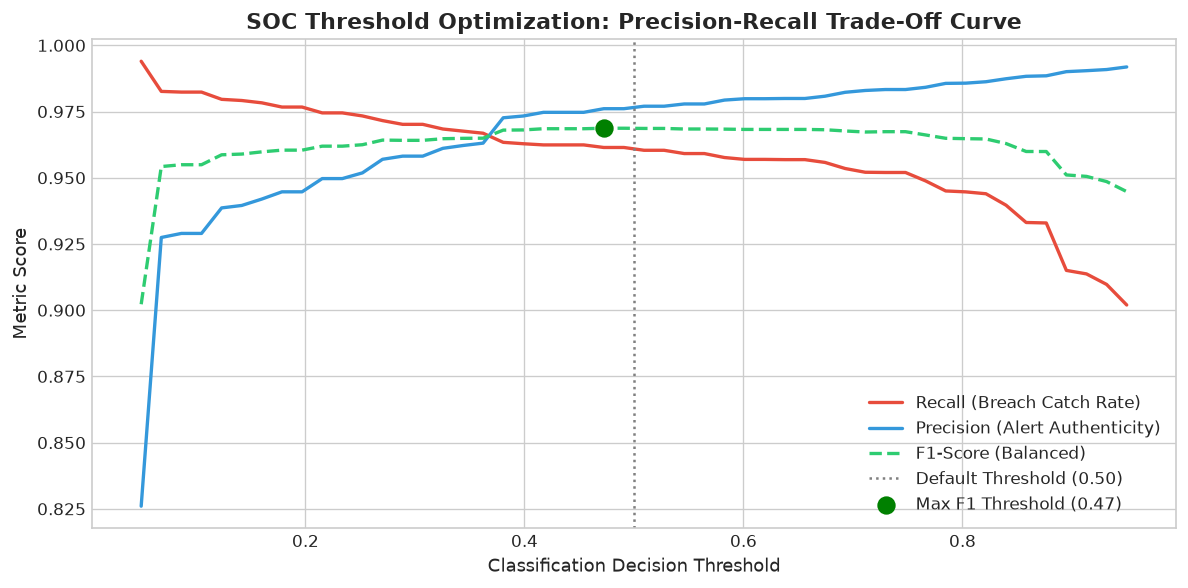

Optimal Threshold for Balanced F1: 0.47 (F1 = 96.87%, Recall = 96.14%)


In [8]:
# Threshold Tuning Curve (Precision vs Recall vs F1)
thresholds = np.linspace(0.05, 0.95, 50)
recs, precs, f1s = [], [], []

for t in thresholds:
    y_t = (y_prob_dt >= t).astype(int)
    recs.append(recall_score(y_val, y_t))
    precs.append(precision_score(y_val, y_t))
    f1s.append(f1_score(y_val, y_t))

plt.figure(figsize=(10, 5))
plt.plot(thresholds, recs, label='Recall (Breach Catch Rate)', color='#E74C3C', lw=2)
plt.plot(thresholds, precs, label='Precision (Alert Authenticity)', color='#3498DB', lw=2)
plt.plot(thresholds, f1s, label='F1-Score (Balanced)', color='#2ECC71', lw=2, linestyle='--')
plt.axvline(x=0.5, color='gray', linestyle=':', label='Default Threshold (0.50)')

opt_idx = np.argmax(f1s)
opt_thresh = thresholds[opt_idx]
plt.scatter([opt_thresh], [f1s[opt_idx]], color='green', s=100, zorder=5, label=f'Max F1 Threshold ({opt_thresh:.2f})')

plt.title('SOC Threshold Optimization: Precision-Recall Trade-Off Curve', fontsize=13, weight='bold')
plt.xlabel('Classification Decision Threshold', fontsize=11)
plt.ylabel('Metric Score', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Optimal Threshold for Balanced F1: {opt_thresh:.2f} (F1 = {f1s[opt_idx]*100:.2f}%, Recall = {recs[opt_idx]*100:.2f}%)")


## 💡 8. Summary & Transition to Deep Learning
1. **Decision Tree Superiority**: Achieves **96.57% accuracy**, **96.04% recall**, and **2.77% false alarm rate**, training in just **~2.5 seconds**.
2. **White-Box Security Rules**: High-Gini features (`sttl`, `ct_state_ttl`, `dmean`, `sbytes`) provide explicit heuristic rules for inline firewall filters.
3. **Fuzzer Evasion**: Fuzzers show the lowest recall ($82.2\%$) due to payload randomization designed specifically to evade signature and tree boundaries.
4. **Next Step**: In `03_deep_learning_and_soc_benchmarks.ipynb`, we evaluate whether a Multi-Layer Perceptron neural network can capture complex non-linear patterns, benchmark training and inference latencies, and evaluate out-of-sample generalization.
